# Modelos de clasificación para detección temprana de fraude en entidades bancarias
## Notebook 06 — Comparación de modelos y selección final

Reúne los resultados guardados por los notebooks 02 a 05 (`artefactos/resultados_*.json`) para responder:

1. **¿Qué modelo ordena mejor a los clientes por riesgo de fraude?** (AUC en los **mismos folds**, del torneo del Notebook 05)
2. **¿Es estable?** (Metodología 1 vs 2 y brecha Train-Test)
3. **¿Ayuda el balanceo de clases?**
4. **¿Cuánto aporta `pos_ID`** (orden del ID) y qué riesgo tiene?
5. **¿Qué archivos subir a Kaggle?**

No se entrena ningún modelo: solo se leen resultados y predicciones ya guardadas, así que corre en segundos.

## 0. Librerías y configuración

In [12]:
import os, sys, json
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Un color fijo por modelo (paleta validada para daltonismo); se usa igual en todos los gráficos
MODELOS = ["Regresión Logística", "Random Forest", "XGBoost", "Ensamble"]
COLOR = {"Regresión Logística": "#2a78d6", "Random Forest": "#eb6834", "XGBoost": "#1baf7a", "Ensamble": "#eda100"}
GRIS, TEXTO = "#a3a29c", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GRIS,
                     "axes.labelcolor": TEXTO, "xtick.color": TEXTO, "ytick.color": TEXTO,
                     "axes.grid": True, "grid.color": "#e8e7e3", "grid.linewidth": 0.8, "axes.axisbelow": True})

In [13]:
if "google.colab" in sys.modules:
    DATA_DIR, ART_DIR = "/content/data/", "/content/artefactos/"
elif "DATABRICKS_RUNTIME_VERSION" in os.environ:
    DATA_DIR, ART_DIR = "/Volumes/main/default/fraude/", "/Volumes/main/default/fraude/artefactos/"
else:
    # Docker / local: busca la carpeta data/ (con train.csv) aquí o en las carpetas de arriba
    carpeta = os.path.abspath(".")
    while not os.path.exists(os.path.join(carpeta, "data", "train.csv")) and carpeta != os.path.dirname(carpeta):
        carpeta = os.path.dirname(carpeta)
    DATA_DIR = os.path.join(carpeta, "data", "")
    ART_DIR = "./artefactos/"
SUB_DIR = "./submissions/"
os.makedirs(ART_DIR, exist_ok=True)
os.makedirs(SUB_DIR, exist_ok=True)
DATA_DIR

'/work/data/'

## 1. Resultados de cada notebook

In [14]:
archivos = {"Regresión Logística": "logistica", "Random Forest": "rforest", "XGBoost": "xgboost", "Ensamble": "ensamble"}
res = {m: json.load(open(ART_DIR + f"resultados_{a}.json", encoding="utf-8")) for m, a in archivos.items()}

def completo(m, balanceo):
    fila = [r for r in res[m]["completo"] if r["Modelo"] == ("Con balanceo" if balanceo else "Sin balanceo")]
    return fila[0]

resumen = pd.DataFrame([{
    "Modelo": m,
    "AUC Test Met. 1": res[m]["estabilidad"][0]["AUC Test"],
    "AUC Test Met. 2": res[m]["estabilidad"][1]["AUC Test"],
    "Brecha Train-Test (media)": np.mean([e["Brecha Train-Test"] for e in res[m]["estabilidad"]]),
    "AUC CV sin balanceo": completo(m, False)["AUC CV (media)"],
    "AUC CV con balanceo": completo(m, True)["AUC CV (media)"],
    "AUC CV con pos_ID": res[m]["auc_cv_con_posID"],
    "AUC Test con 0/1 (predict)": np.mean([e["AUC Test con 0/1"] for e in res[m]["estabilidad"]]),
} for m in MODELOS]).set_index("Modelo")
resumen.round(4)

,AUC Test Met. 1,AUC Test Met. 2,Brecha Train-Test (media),AUC CV sin balanceo,AUC CV con balanceo,AUC CV con pos_ID,AUC Test con 0/1 (predict)
Modelo,,,,,,,
Regresión Logística,0.9231,0.9235,0.0001,0.9233,0.9236,0.9433,0.6793
Random Forest,0.9316,0.9319,0.0121,0.9322,0.9288,0.9559,0.6815
XGBoost,0.9340,0.9344,0.0033,0.9331,0.9272,0.9580,0.6886
Ensamble,0.9335,0.9338,0.0081,0.9310,0.9285,0.9567,0.6852


> **Nota:** las columnas *AUC CV* de esta tabla vienen de cada notebook, que usan submuestras distintas para la búsqueda (Logística: toda la base; Random Forest: 20%; XGBoost: 40%; Ensamble: 20%). Sirven para ver **tendencias dentro de cada modelo** (balanceo, `pos_ID`), pero la comparación **entre modelos** se hace con el torneo de la sección 2, donde todos usan los mismos datos y folds.

## 2. ¿Qué modelo ordena mejor? Torneo en los mismos folds (Notebook 05)
Todos los candidatos se evaluaron con la misma submuestra estratificada y los mismos 3 folds. La línea muestra el rango entre el peor y el mejor fold.

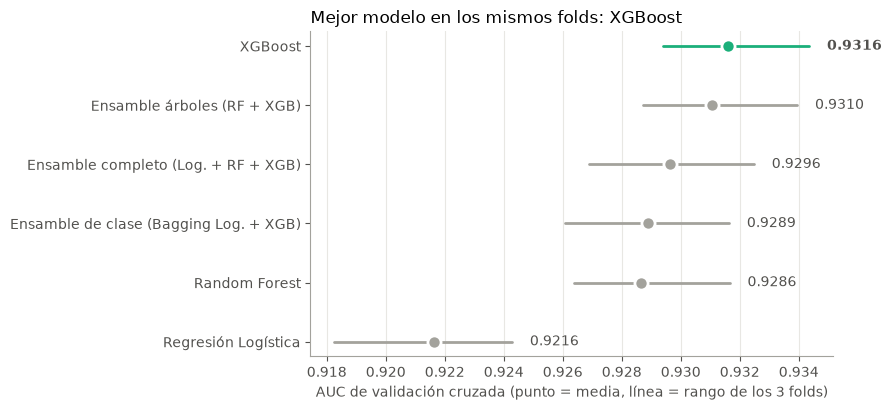

,AUC CV (media),AUC CV (desv.)
Candidato,,
XGBoost,0.9316,0.0021
Ensamble árboles (RF + XGB),0.9310,0.0022
Ensamble completo (Log. + RF + XGB),0.9296,0.0023
Ensamble de clase (Bagging Log. + XGB),0.9289,0.0023
Random Forest,0.9286,0.0022
Regresión Logística,0.9216,0.0025


In [15]:
torneo = pd.DataFrame(res["Ensamble"]["torneo"]).set_index("Candidato")
folds = pd.DataFrame(res["Ensamble"]["folds_torneo"])
orden = torneo.sort_values("AUC CV (media)").index
mejor = orden[-1]

fig, ax = plt.subplots(figsize=(9, 4.2))
for i, cand in enumerate(orden):
    f = folds[cand]
    color = COLOR["XGBoost"] if cand == mejor else GRIS
    ax.plot([f.min(), f.max()], [i, i], color=color, lw=2, solid_capstyle="round")
    ax.scatter(f.mean(), i, s=90, color=color, zorder=3, edgecolor="white", linewidth=2)
    ax.text(f.max() + 0.0006, i, f"{f.mean():.4f}", va="center", color=TEXTO, fontsize=10,
            fontweight="bold" if cand == mejor else "normal")
ax.set_yticks(range(len(orden))); ax.set_yticklabels(orden); ax.grid(axis="y", visible=False)
ax.set_xlabel("AUC de validación cruzada (punto = media, línea = rango de los 3 folds)")
ax.set_title(f"Mejor modelo en los mismos folds: {mejor}", loc="left", fontsize=12)
plt.tight_layout(); plt.show()
torneo.sort_values("AUC CV (media)", ascending=False).round(4)

In [16]:
dif = torneo.loc[mejor, "AUC CV (media)"] - torneo["AUC CV (media)"].drop(mejor).max()
segundo = torneo["AUC CV (media)"].drop(mejor).idxmax()
print(f"{mejor} supera a {segundo} por {dif:.4f} de AUC; la desviación entre folds es ±{torneo.loc[mejor, 'AUC CV (desv.)']:.4f}.")
print("→ Diferencia dentro del ruido: en la práctica empatan." if dif < torneo.loc[mejor, "AUC CV (desv.)"] else "→ Diferencia mayor que el ruido entre folds.")

XGBoost supera a Ensamble árboles (RF + XGB) por 0.0006 de AUC; la desviación entre folds es ±0.0021.
→ Diferencia dentro del ruido: en la práctica empatan.


## 3. ¿Es estable? Metodología 1 vs 2 y brecha Train-Test
Un modelo estable tiene AUC de Test parecida en las dos metodologías (no depende de qué mitad de los datos se use) y poca distancia entre Train y Test (no sobreajusta).

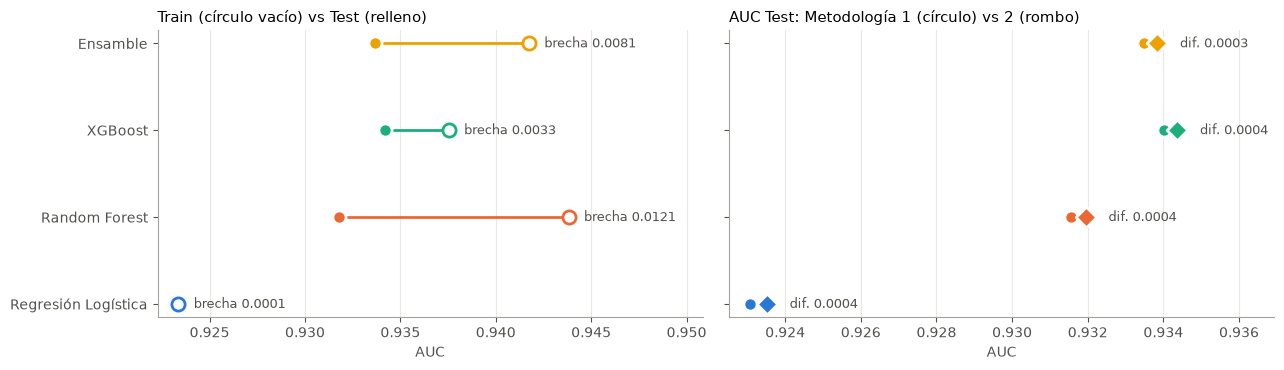

,AUC Test Met. 1,AUC Test Met. 2,Brecha Train-Test (media)
Modelo,,,
Regresión Logística,0.9231,0.9235,0.0001
Random Forest,0.9316,0.9319,0.0121
XGBoost,0.9340,0.9344,0.0033
Ensamble,0.9335,0.9338,0.0081


In [17]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for i, m in enumerate(MODELOS):
    e = res[m]["estabilidad"]
    tr = np.mean([x["AUC Train"] for x in e]); te = np.mean([x["AUC Test"] for x in e])
    ax[0].plot([te, tr], [i, i], color=COLOR[m], lw=2, solid_capstyle="round")
    ax[0].scatter(te, i, s=90, color=COLOR[m], zorder=3, edgecolor="white", linewidth=2)
    ax[0].scatter(tr, i, s=90, facecolor="white", edgecolor=COLOR[m], linewidth=2, zorder=3)
    ax[0].text(tr + 0.0008, i, f"brecha {tr - te:.4f}", va="center", color=TEXTO, fontsize=9)
    m1, m2 = e[0]["AUC Test"], e[1]["AUC Test"]
    ax[1].scatter([m1], [i], s=90, color=COLOR[m], marker="o", edgecolor="white", linewidth=2, zorder=3)
    ax[1].scatter([m2], [i], s=110, color=COLOR[m], marker="D", edgecolor="white", linewidth=2, zorder=3)
    ax[1].text(max(m1, m2) + 0.0006, i, f"dif. {abs(m1 - m2):.4f}", va="center", color=TEXTO, fontsize=9)
for a in ax:
    a.set_yticks(range(len(MODELOS))); a.set_yticklabels(MODELOS); a.grid(axis="y", visible=False)
ax[1].set_yticklabels([])
ax[0].set_title("Train (círculo vacío) vs Test (relleno)", loc="left", fontsize=11); ax[0].set_xlabel("AUC")
ax[1].set_title("AUC Test: Metodología 1 (círculo) vs 2 (rombo)", loc="left", fontsize=11); ax[1].set_xlabel("AUC")
ax[0].set_xlim(right=ax[0].get_xlim()[1] + 0.006); ax[1].set_xlim(right=ax[1].get_xlim()[1] + 0.002)
plt.tight_layout(); plt.show()
resumen[["AUC Test Met. 1", "AUC Test Met. 2", "Brecha Train-Test (media)"]].round(4)

## 4. ¿Ayuda el balanceo de clases (SMOTE + undersampling)?

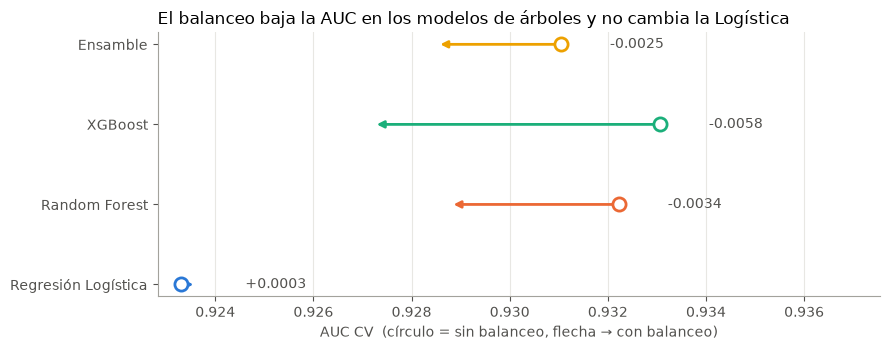

,AUC CV sin balanceo,AUC CV con balanceo,Diferencia
Modelo,,,
Regresión Logística,0.9233,0.9236,0.0003
Random Forest,0.9322,0.9288,-0.0034
XGBoost,0.9331,0.9272,-0.0058
Ensamble,0.9310,0.9285,-0.0025


In [18]:
def comparar_dos(col_a, col_b, etiqueta_a, etiqueta_b, titulo):
    fig, ax = plt.subplots(figsize=(9, 3.6))
    for i, m in enumerate(MODELOS):
        a, b = resumen.loc[m, col_a], resumen.loc[m, col_b]
        ax.annotate("", xy=(b, i), xytext=(a, i), arrowprops=dict(arrowstyle="-|>", color=COLOR[m], lw=2))
        ax.scatter(a, i, s=90, facecolor="white", edgecolor=COLOR[m], linewidth=2, zorder=3)
        ax.text(max(a, b) + 0.001, i, f"{b - a:+.4f}", va="center", color=TEXTO, fontsize=10)
    ax.set_yticks(range(len(MODELOS))); ax.set_yticklabels(MODELOS); ax.grid(axis="y", visible=False)
    ax.set_xlim(right=ax.get_xlim()[1] + 0.004)
    ax.set_xlabel(f"AUC CV  (círculo = {etiqueta_a}, flecha → {etiqueta_b})")
    ax.set_title(titulo, loc="left", fontsize=12); plt.tight_layout(); plt.show()

comparar_dos("AUC CV sin balanceo", "AUC CV con balanceo", "sin balanceo", "con balanceo",
             "El balanceo baja la AUC en los modelos de árboles y no cambia la Logística")
resumen[["AUC CV sin balanceo", "AUC CV con balanceo"]].assign(Diferencia=lambda d: d.iloc[:, 1] - d.iloc[:, 0]).round(4)

**¿Por qué el balanceo no ayuda?** La AUC solo mide el **orden** de las probabilidades. SMOTE crea fraudes sintéticos y el undersampling descarta clientes reales, lo que cambia la **escala** de las probabilidades (por eso el umbral pasa de ~0.06 a ~0.4 y la AUC con 0/1 mejora), pero no mejora el orden y además añade ruido. En la Regresión Logística el cambio es mínimo (+0.0003), y en Random Forest, XGBoost y el Ensamble la AUC baja. Para Kaggle, que evalúa AUC con probabilidades, conviene **no balancear**.

## 5. ¿Cuánto aporta `pos_ID` (orden del ID)?

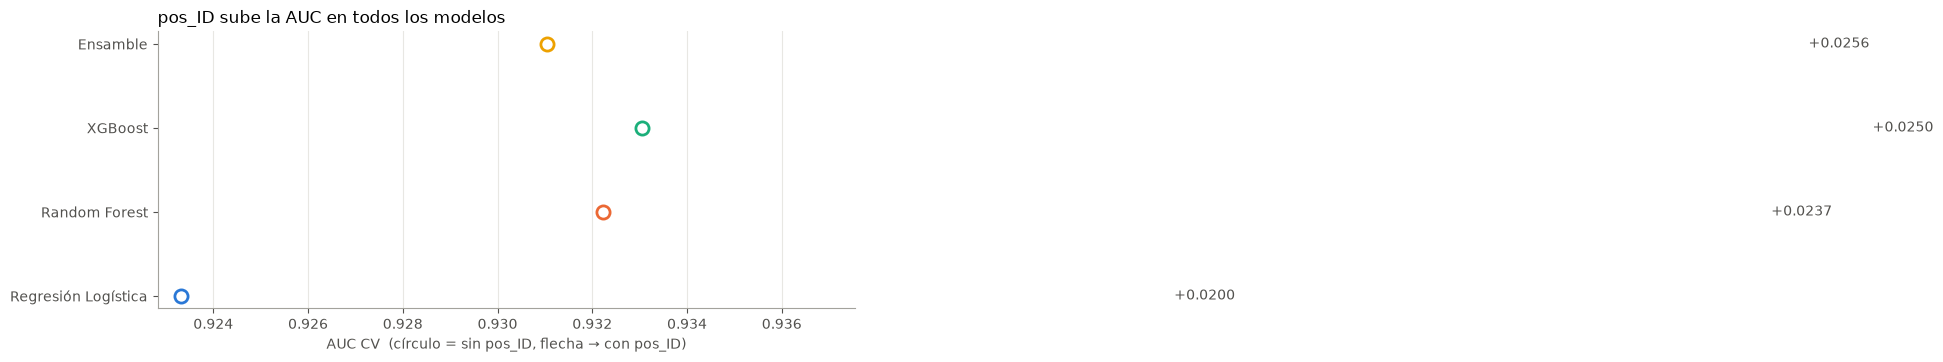

,AUC CV sin balanceo,AUC CV con pos_ID,Diferencia
Modelo,,,
Regresión Logística,0.9233,0.9433,0.0200
Random Forest,0.9322,0.9559,0.0237
XGBoost,0.9331,0.9580,0.0250
Ensamble,0.9310,0.9567,0.0256


In [19]:
comparar_dos("AUC CV sin balanceo", "AUC CV con pos_ID", "sin pos_ID", "con pos_ID",
             "pos_ID sube la AUC en todos los modelos")
resumen[["AUC CV sin balanceo", "AUC CV con pos_ID"]].assign(Diferencia=lambda d: d.iloc[:, 1] - d.iloc[:, 0]).round(4)

**Riesgo de `pos_ID`:** el fraude se concentra en los últimos `ID` de cada grupo (Estado, Género, Tipo de tarjeta). Es un patrón de **cómo se construyó la base**, no del comportamiento del cliente: en producción un cliente nuevo no "sabe" su posición en la lista. Por eso es una **fuga de información (*data leakage*)**: mejora la AUC en Kaggle, pero el modelo no la tendría en un banco real. Si se usa, debe declararse explícitamente en la presentación.

## 6. ¿Por qué el ensamble no mejora? Correlación entre las predicciones
Un ensamble solo ayuda si los modelos se equivocan **en clientes distintos**. Se mide la correlación de Spearman (de **orden**, igual que la AUC) entre las probabilidades que cada modelo asignó a los clientes del test de Kaggle.

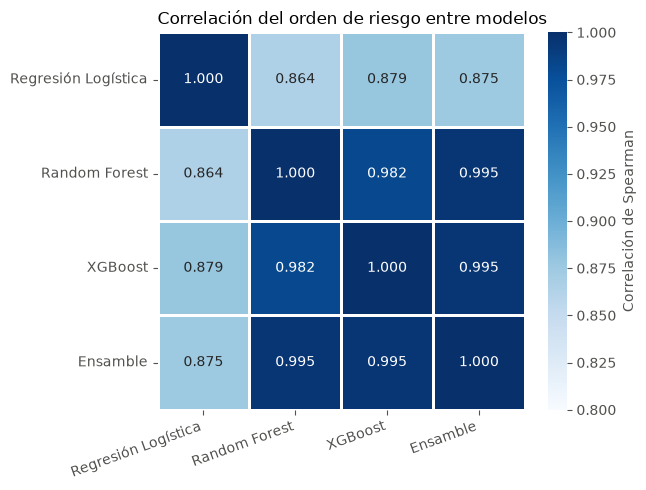

Random Forest vs XGBoost: 0.982


In [20]:
subs = {m: pd.read_csv(SUB_DIR + f"submission_{a}_no_balanceo.csv")["Fraude"] for m, a in archivos.items()}
corr = pd.DataFrame(subs).corr(method="spearman")

plt.figure(figsize=(6.5, 5))
sns.heatmap(corr, annot=True, fmt=".3f", cmap="Blues", vmin=0.8, vmax=1, linewidths=2, linecolor="white",
            cbar_kws={"label": "Correlación de Spearman"})
plt.title("Correlación del orden de riesgo entre modelos", loc="left", fontsize=12)
plt.xticks(rotation=20, ha="right"); plt.yticks(rotation=0); plt.tight_layout(); plt.show()
print(f"Random Forest vs XGBoost: {corr.loc['Random Forest', 'XGBoost']:.3f}")

## 7. Archivos para Kaggle
Se ordenan las submissions por la AUC estimada del modelo (torneo para la versión sin balanceo; AUC CV de cada notebook para las demás). Kaggle permite **5 envíos por día** y la calificación es la AUC (> 0.95 → 5.0).

> Las AUC estimadas vienen de fuentes distintas (torneo para *sin balanceo*, cada notebook para *con balanceo* y *con pos_ID*), así que diferencias menores a ~0.002 no son significativas. La AUC real la da el *Public Score* de Kaggle.

In [21]:
filas = []
for m, a in archivos.items():
    base_cv = torneo.loc[m if m != "Ensamble" else res["Ensamble"]["ensamble_elegido"], "AUC CV (media)"]
    filas += [{"Archivo": f"submission_{a}_no_balanceo.csv", "Modelo": m, "Variante": "sin balanceo", "AUC estimada": base_cv, "Usa pos_ID": "No"},
              {"Archivo": f"submission_{a}_balanceo.csv", "Modelo": m, "Variante": "con balanceo", "AUC estimada": resumen.loc[m, "AUC CV con balanceo"], "Usa pos_ID": "No"},
              {"Archivo": f"submission_{a}_con_posID.csv", "Modelo": m, "Variante": "con pos_ID", "AUC estimada": res[m]["auc_cv_con_posID"], "Usa pos_ID": "Sí (fuga)"}]
ranking = pd.DataFrame(filas)
ranking = ranking[ranking["Archivo"].apply(lambda f: os.path.exists(SUB_DIR + f))]
ranking = ranking.sort_values("AUC estimada", ascending=False).reset_index(drop=True)
ranking.index += 1
ranking.round(4)

,Archivo,Modelo,Variante,AUC estimada,Usa pos_ID
1,submission_xgboost_con_posID.csv,XGBoost,con pos_ID,0.9580,Sí (fuga)
2,submission_ensamble_con_posID.csv,Ensamble,con pos_ID,0.9567,Sí (fuga)
3,submission_rforest_con_posID.csv,Random Forest,con pos_ID,0.9559,Sí (fuga)
4,submission_logistica_con_posID.csv,Regresión Logística,con pos_ID,0.9433,Sí (fuga)
5,submission_xgboost_no_balanceo.csv,XGBoost,sin balanceo,0.9316,No
6,submission_ensamble_no_balanceo.csv,Ensamble,sin balanceo,0.9310,No
7,submission_rforest_balanceo.csv,Random Forest,con balanceo,0.9288,No
8,submission_rforest_no_balanceo.csv,Random Forest,sin balanceo,0.9286,No
9,submission_ensamble_balanceo.csv,Ensamble,con balanceo,0.9285,No
10,submission_xgboost_balanceo.csv,XGBoost,con balanceo,0.9272,No


In [22]:
sin_fuga = ranking[ranking["Usa pos_ID"] == "No"].iloc[0]
con_fuga = ranking[ranking["Usa pos_ID"] != "No"].iloc[0]
print(f"Mejor sin pos_ID: {sin_fuga['Archivo']}  (AUC estimada {sin_fuga['AUC estimada']:.4f})")
print(f"Mejor con pos_ID: {con_fuga['Archivo']}  (AUC estimada {con_fuga['AUC estimada']:.4f})")

Mejor sin pos_ID: submission_xgboost_no_balanceo.csv  (AUC estimada 0.9316)
Mejor con pos_ID: submission_xgboost_con_posID.csv  (AUC estimada 0.9580)


## 8. Conclusiones

1. **Mejor modelo: XGBoost.** En los mismos folds obtiene la mayor AUC (0.9316), seguido muy de cerca por el ensamble Random Forest + XGBoost (0.9311). La diferencia (0.0005) es menor que la variación entre folds (±0.002): en la práctica empatan, y XGBoost es más simple y rápido.
2. **Es estable.** La AUC de Test de XGBoost es 0.9340 (Metodología 1) y 0.9344 (Metodología 2), con una brecha Train-Test de solo 0.003: no depende de qué mitad de los datos se use y no sobreajusta. Random Forest tiene la brecha más alta (0.010).
3. **El ensamble no mejora** porque Random Forest y XGBoost ordenan a los clientes casi igual (correlación de Spearman 0.98): se equivocan en los mismos casos, así que promediarlos no aporta información nueva.
4. **El balanceo no ayuda a la AUC.** Baja la AUC de los modelos de árboles (XGBoost −0.006, Ensamble −0.008) y no cambia la Logística. Solo mejora la AUC calculada con 0/1, que no es la métrica de Kaggle.
5. **Usar probabilidades, no 0/1.** Con `predict()` la AUC cae a ~0.68 en todos los modelos; con `predict_proba()` es ~0.93.
6. **`pos_ID` sube la AUC unos 0.025 en todos los modelos** (XGBoost: 0.958, por encima de 0.95), pero es una **fuga de información** por el orden en que se construyó la base; no estaría disponible en un banco real. Si se usa en Kaggle, debe declararse como riesgo en la presentación.

**Recomendación para Kaggle:** subir `submission_xgboost_no_balanceo.csv` como modelo honesto y, si el equipo decide usar `pos_ID`, `submission_xgboost_con_posID.csv`, explicando la fuga.